# Part I – Loading and Exploring the Iris Dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.cluster import MiniBatchKMeans

# Imports – Purpose of Each Library

**1. `numpy` (as `np`)**
**Answer:** Fast maths on arrays of numbers. Our data is stored as NumPy arrays, and we use it to build the grid for the decision-boundary plot.

**2. `matplotlib.pyplot` (as `plt`)**
**Answer:** Draws the charts: scatter plots, the boundary regions and the elbow curve.

**3. `load_iris`**
**Answer:** Loads the built-in Iris flower dataset (150 flowers, 4 measurements each, plus species labels).

**4. `KMeans`**
**Answer:** The standard K-Means clustering algorithm. It groups data into k clusters with no labels needed.

**5. `MiniBatchKMeans`**
**Answer:** A faster version of K-Means that learns from small random chunks (mini-batches) of the data instead of the whole dataset every step. Useful for very large datasets.

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Feature names:", iris.feature_names)

Shape of X: (150, 4)
Shape of y: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


# Task 1.1 – Interpretation

**1. How many observations are in the dataset?**
**Answer:** 150 flowers. `X.shape` is (150, 4), so there are 150 rows.

**2. How many features does each observation contain?**
**Answer:** 4: sepal length, sepal width, petal length and petal width (all in cm).

**3. Why should the target variable not be used when performing unsupervised clustering?**
**Answer:** Unsupervised learning means the model has to find the groups on its own, with no answer key. If we give it `y`, we are telling it the answers, so it is no longer unsupervised. We also keep `y` hidden so we can use it *afterwards* to check how good the discovered groups were.

**4. What would happen conceptually if we used the known species labels to train a model?**
**Answer:** It would become supervised learning (classification), like the SVM in Lab IV. The model would learn to copy our labels instead of discovering structure by itself. That is a different task with a different goal.

# Part II – Creating Data for K-Means Clustering

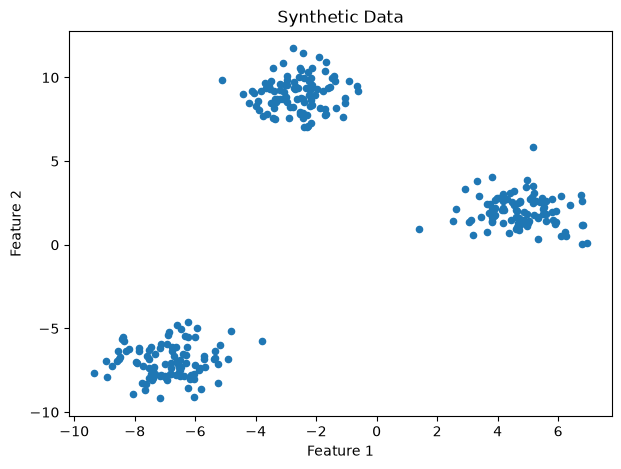

In [3]:
from sklearn.datasets import make_blobs

X_blobs, y_blobs = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], s=20)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Data")
plt.show()

# Task 2.1 – Interpretation

**1. How many groups appear to exist in the data?**
**Answer:** 3 clear groups: one at the top (around x=−2.6, y=9), one bottom-left (around −6.9, −7) and one on the right (around 4.7, 2).

**2. What visual characteristics make the groups distinguishable?**
**Answer:** Each group is a tight, round blob of points, and there is a lot of empty space between the blobs. No points sit in the gaps, so you can draw a circle around each group by eye.

**3. Why is this dataset easier to visualize than the original Iris dataset?**
**Answer:** It has only 2 features, so it fits perfectly on a flat x–y plot. Iris has 4 features (4 dimensions), which we cannot draw on one chart. We can only plot 2 of the 4 at a time. Also, the blobs were generated to be well separated, while two of the Iris species overlap.

**4. What does the parameter `cluster_std` control?**
**Answer:** How spread out each blob is (its standard deviation). Small values give tight, compact blobs. Large values give wide, fuzzy blobs that start to overlap. Here `cluster_std=1.0`.

# Part III – K-Means Clustering

In [4]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_blobs)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[-2.

In [5]:
print("Cluster centers:")
print(kmeans.cluster_centers_)

Cluster centers:
[[-2.63323268  9.04356978]
 [-6.88387179 -6.98398415]
 [ 4.74710337  2.01059427]]


In [6]:
cluster_labels = kmeans.predict(X_blobs)

print(cluster_labels[:20])

[1 1 0 2 1 2 0 2 0 0 0 2 0 0 1 0 1 2 0 0]


In [7]:
cluster_labels = kmeans.labels_
print("Points per cluster:", np.bincount(cluster_labels))

Points per cluster: [100 100 100]


# Task 3.1 – Interpretation

**1. What do the numbers 0, 1, and 2 represent?**
**Answer:** Which cluster each point was put into. For example, the first point is in cluster 1, the third point is in cluster 0. Each cluster got exactly 100 points.

**2. Do these numbers have any inherent meaning?**
**Answer:** No. They are just name tags, like naming three teams Red, Blue and Green. Swap the names around and the grouping is exactly the same. With another random seed, the same blob could be called 2 instead of 0.

**3. Why should cluster number 0 not automatically be interpreted as “the first class”?**
**Answer:** K-Means never saw the true labels, so it has no idea what “class 0” is. The numbers come from the order in which it happened to create its centres. Here, cluster 0 is the top blob, but in `y_blobs` the top blob is also 0 only by luck: cluster 1 is true blob 2, and cluster 2 is true blob 1.

**4. What information is represented by cluster centers?**
**Answer:** The centre point (the average position) of each cluster. Each row is the (Feature 1, Feature 2) coordinates of one centroid: about (−2.63, 9.04), (−6.88, −6.98) and (4.75, 2.01). A centroid is the “typical” member of its group.

# Part IV – Visualizing Clusters and Decision Boundaries

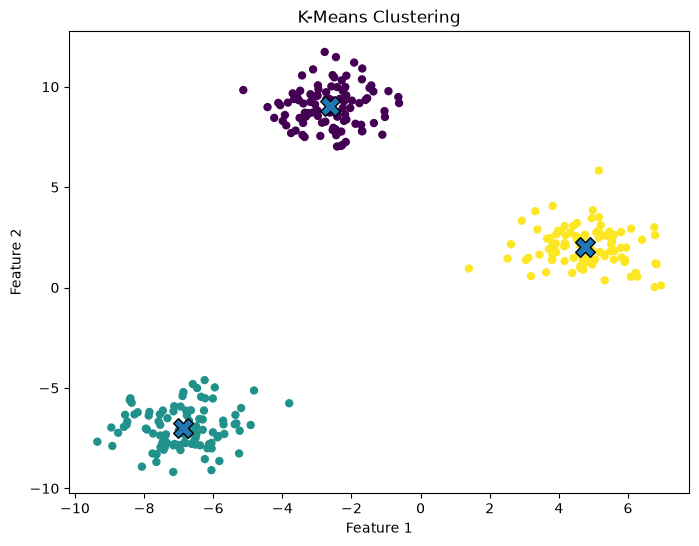

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_blobs[:, 0],
    X_blobs[:, 1],
    c=cluster_labels,
    s=25
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200,
    edgecolor="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.show()

In [9]:
# Extra check: how far is each point from its own centroid?
distances = np.linalg.norm(X_blobs - kmeans.cluster_centers_[cluster_labels], axis=1)
print("Closest point:  ", distances.min().round(2))
print("Average point:  ", distances.mean().round(2))
print("Furthest point: ", distances.max().round(2))

Closest point:   0.1
Average point:   1.22
Furthest point:  3.84


# Task 4.1 – Interpretation

**1. Where are the cluster centers located?**
**Answer:** Right in the middle of each blob (the big X markers): about (−2.6, 9.0) at the top, (−6.9, −7.0) bottom-left and (4.7, 2.0) on the right.

**2. Which observations are assigned to each cluster?**
**Answer:** Every point is assigned to the blob it visually belongs to: all points in the top blob get one colour, the bottom-left another, the right one another. 100 points each.

**3. Are all observations equally close to their cluster center?**
**Answer:** No. The closest point is only 0.10 away, the average is 1.22, and the furthest is 3.84. Points on the outer edge of a blob are further from the centre than points in the middle.

**4. Are there observations that appear close to the boundary between clusters?**
**Answer:** Not really. The blobs are far apart, so even the outermost points are much closer to their own centre than to any other centre. A few edge points lean toward the gap, but none are in doubt.

In [10]:
x_min, x_max = X_blobs[:, 0].min() - 1, X_blobs[:, 0].max() + 1
y_min, y_max = X_blobs[:, 1].min() - 1, X_blobs[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = kmeans.predict(grid)

Z = Z.reshape(xx.shape)

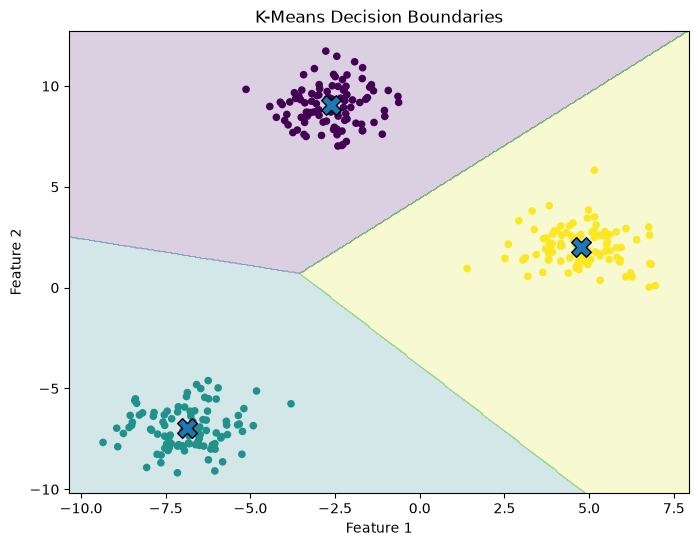

In [11]:
plt.figure(figsize=(8, 6))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.2
)

plt.scatter(
    X_blobs[:, 0],
    X_blobs[:, 1],
    c=cluster_labels,
    s=20
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200,
    edgecolor="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Decision Boundaries")
plt.show()

# Task 4.2 – Interpretation

**1. What does each region in the plot represent?**
**Answer:** The area of the map that belongs to one centroid. Any new point dropped anywhere in that coloured region would be assigned to that cluster.

**2. How are the boundaries related to the cluster centers?**
**Answer:** Each boundary is a straight line exactly halfway between two centroids (at right angles to the line joining them). Every spot on the boundary is equally far from both centres. This pattern is called a Voronoi diagram.

**3. Why are the boundaries determined by distance to the centroids?**
**Answer:** Because that is the K-Means rule: a point always joins the nearest centroid. So the border is simply where “nearest” switches from one centre to another.

**4. What happens to the boundaries if the centroids move?**
**Answer:** The boundaries move with them. The boundaries are always the halfway lines between centroids, so if a centroid moves, the border lines around it shift and turn. Some points near the border may then change cluster.

# Part V – Evaluating K-Means

In [12]:
print("Inertia:", kmeans.inertia_)

Inertia: 566.8595511244131


# Task 5.1 – Interpretation

**1. What does the inertia measure?**
**Answer:** How tightly packed the clusters are. For every point, take the distance to its own centroid, square it, then add them all up. Here it is about 566.86. Lower means points sit closer to their centres.

**2. Does a smaller inertia generally indicate more compact clusters?**
**Answer:** Yes, if you compare models with the same k on the same data. Smaller inertia means the points are, on average, closer to their centroids.

**3. Why can inertia not be used by itself to determine the best number of clusters?**
**Answer:** Inertia always goes down when you add more clusters. In the extreme, if every point is its own cluster (k=300), inertia is 0. So “lowest inertia” would always pick the biggest k, which is useless. You need another method, like the elbow in Part VIII.

# Part VI – Random Initialization and Stability

In [13]:
for seed in [0, 1, 2, 3, 4]:

    model = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=1
    )

    model.fit(X_blobs)

    print(
        "Random state:",
        seed,
        "Inertia:",
        model.inertia_
    )

Random state: 0 Inertia: 566.8595511244131
Random state: 1 Inertia: 566.8595511244131
Random state: 2 Inertia: 566.8595511244131
Random state: 3 Inertia: 566.8595511244131
Random state: 4 Inertia: 566.8595511244131


In [14]:
# Extra experiment: the same loop with plain random starting centres
# (the default above is init="k-means++", which picks smart starting points)
for seed in [0, 1, 2, 3, 4]:
    model = KMeans(n_clusters=3, random_state=seed, n_init=1, init="random")
    model.fit(X_blobs)
    print("Random state:", seed, "Inertia:", round(model.inertia_, 2))

Random state: 0 Inertia: 5695.07
Random state: 1 Inertia: 5693.48
Random state: 2 Inertia: 566.86
Random state: 3 Inertia: 566.86
Random state: 4 Inertia: 566.86


# Task 6.1 – Interpretation

**1. Are the results identical?**
**Answer:** Yes, in this run all 5 seeds gave the same inertia (566.86). That is because scikit-learn uses a smart start called **k-means++** by default, and these blobs are very easy to separate. When I switched to plain random starts (`init="random"`), seeds 0 and 1 got stuck at about 5695 (10 times worse), while seeds 2–4 found 566.86.

**2. Why can different initializations produce different results?**
**Answer:** K-Means only improves step by step from where it starts. If two starting centres land in the same blob, it can get stuck in a bad solution (a *local minimum*) where one centroid sits between two blobs. It never “jumps out” because each small step looks like an improvement.

**3. Which solution would generally be preferred if two solutions have different inertia values?**
**Answer:** The one with the lower inertia, because its clusters are more compact. Here 566.86 is clearly better than 5695.

**4. Why is reproducibility important when experimenting with machine learning algorithms?**
**Answer:** Setting `random_state` makes the random choices the same every time, so you (or your lecturer) get exactly the same numbers when running the code again. That makes results checkable, lets you compare experiments fairly and makes bugs easier to find.

In [15]:
kmeans_multi = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_multi.fit(X_blobs)

print("Inertia:", kmeans_multi.inertia_)

Inertia: 566.8595511244131


In [16]:
kmeans_single = KMeans(n_clusters=3, random_state=42, n_init=1).fit(X_blobs)
print("n_init=1  Inertia:", kmeans_single.inertia_)
print("n_init=10 Inertia:", kmeans_multi.inertia_)

n_init=1  Inertia: 566.8595511244131
n_init=10 Inertia: 566.8595511244131


# Task 6.2 – Interpretation

**1. What is the purpose of `n_init`?**
**Answer:** It is how many times K-Means is run from different starting centres. It keeps the run with the lowest inertia. Here n_init=1 and n_init=10 both gave 566.86, because the data is easy and k-means++ already started well.

**2. Why can multiple initializations improve the result?**
**Answer:** Each run might get stuck in a bad solution. Trying 10 different starts is like taking 10 shots instead of 1: the chance that *all* of them are bad is very small, and we keep the best one.

**3. What is the trade-off of increasing the number of initializations?**
**Answer:** More time and computing power. n_init=10 does roughly 10 times the work of n_init=1. On easy data like this, it gives no gain. On big, messy data it can be worth it.

# Part VII – Mini-Batch K-Means

In [17]:
mini_batch_kmeans = MiniBatchKMeans(
    n_clusters=3,
    random_state=42,
    batch_size=50,
    n_init=10
)

mini_batch_kmeans.fit(X_blobs)

print(
    "Mini-Batch inertia:",
    mini_batch_kmeans.inertia_
)

Mini-Batch inertia: 567.6515143711949


In [18]:
print("Standard K-Means:")
print("Inertia:", kmeans_multi.inertia_)

print("\nMini-Batch K-Means:")
print("Inertia:", mini_batch_kmeans.inertia_)

Standard K-Means:
Inertia: 566.8595511244131

Mini-Batch K-Means:
Inertia: 567.6515143711949


In [19]:
# Extra experiment: speed on a much bigger dataset (500,000 points)
import time

X_big, _ = make_blobs(n_samples=500_000, centers=3, random_state=42)

start = time.time()
big_km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_big)
print(f"Standard K-Means:   {time.time() - start:.2f} s   inertia = {big_km.inertia_:,.0f}")

start = time.time()
big_mb = MiniBatchKMeans(n_clusters=3, random_state=42, batch_size=1024, n_init=10).fit(X_big)
print(f"Mini-Batch K-Means: {time.time() - start:.2f} s   inertia = {big_mb.inertia_:,.0f}")

Standard K-Means:   0.80 s   inertia = 1,000,372
Mini-Batch K-Means: 0.11 s   inertia = 1,000,727


# Task 7.1 – Interpretation

**1. Are the inertia values exactly the same?**
**Answer:** No, but they are very close: 566.86 for standard K-Means and 567.65 for Mini-Batch. Mini-Batch is about 0.14% worse. Both put every point in the same cluster; only the centroids are very slightly shifted.

**2. Why might the results differ?**
**Answer:** Mini-Batch updates the centroids using only 50 random points at a time, not all 300. Each small batch gives a slightly noisy estimate of where the centre should be, so the final centroids land close to, but not exactly on, the best spot.

**3. Why could Mini-Batch K-Means be useful for very large datasets?**
**Answer:** It does not need to look at every point on every step, and it does not need the whole dataset in memory at once. On my 500,000-point test it was roughly 10 times faster than standard K-Means (your times will differ by computer).

**4. What is the potential trade-off between computational speed and clustering quality?**
**Answer:** You get speed but lose a little quality: inertia is slightly higher. On the big test, the inertia was about 0.04% worse. For most large real-world jobs that tiny loss is worth the big time saving, but if you need the most exact centroids, use standard K-Means.

# Part VIII – Finding the Optimal Number of Clusters

In [20]:
inertias = []

for k in range(1, 10):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_blobs)

    inertias.append(model.inertia_)

for k, inertia in zip(range(1, 10), inertias):
    print(f"k={k}  inertia={inertia:,.1f}")

k=1  inertia=20,402.3
k=2  inertia=5,763.5
k=3  inertia=566.9
k=4  inertia=496.4
k=5  inertia=427.1
k=6  inertia=375.0
k=7  inertia=308.2
k=8  inertia=272.4
k=9  inertia=234.3


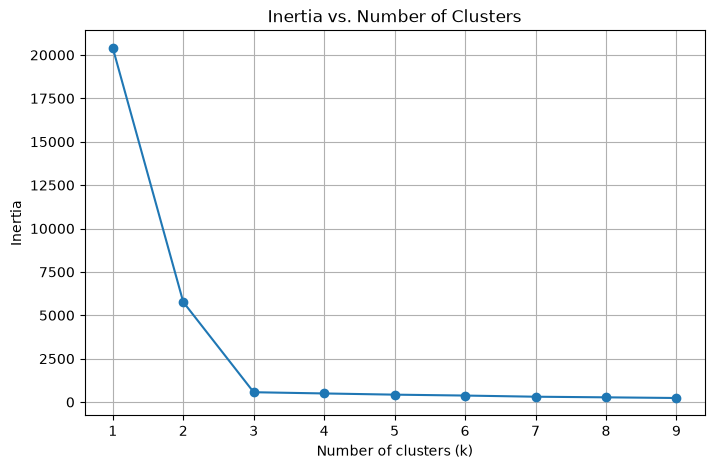

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 10),
    inertias,
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Inertia vs. Number of Clusters")
plt.xticks(range(1, 10))
plt.grid(True)
plt.show()

# Task 8.1 – Interpretation

**1. What happens to inertia when k increases?**
**Answer:** It keeps going down: 20,402 at k=1, 5,764 at k=2, 567 at k=3, then slowly to 234 at k=9.

**2. Why does inertia generally decrease as more clusters are introduced?**
**Answer:** More centroids means every point is likely to have a centre closer to it, so the squared distances get smaller. Adding a centroid can never make the best solution worse.

**3. Where would you place the elbow in this experiment?**
**Answer:** At **k = 3**. From k=2 to k=3, inertia drops by about 5,200 (a huge fall). From k=3 to k=4 it only drops by about 70. After 3, the curve goes almost flat. This matches the 3 blobs we created.

**4. Why would selecting the largest possible k not necessarily be useful?**
**Answer:** It just chops real groups into meaningless small pieces. At k=9 the 3 true blobs are split into 9 fragments, which tells us nothing new. At k=300, every point is its own cluster and inertia is 0, but that is not a useful grouping.

**5. Why is the elbow method a heuristic rather than a guaranteed solution?**
**Answer:** A heuristic is a rule of thumb, not a proof. Picking the elbow is a judgement call by eye. On messy real data the curve often bends smoothly with no clear corner, and two people can pick different k. It works well here only because the blobs are so clean.

# Part IX – Applying K-Means to the Iris Dataset

In [22]:
iris_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

iris_kmeans.fit(X)

iris_clusters = iris_kmeans.labels_

print("Cluster centers:")
print(iris_kmeans.cluster_centers_)

print("\nInertia:")
print(iris_kmeans.inertia_)

Cluster centers:
[[5.9016129  2.7483871  4.39354839 1.43387097]
 [5.006      3.428      1.462      0.246     ]
 [6.85       3.07368421 5.74210526 2.07105263]]

Inertia:
78.85144142614601


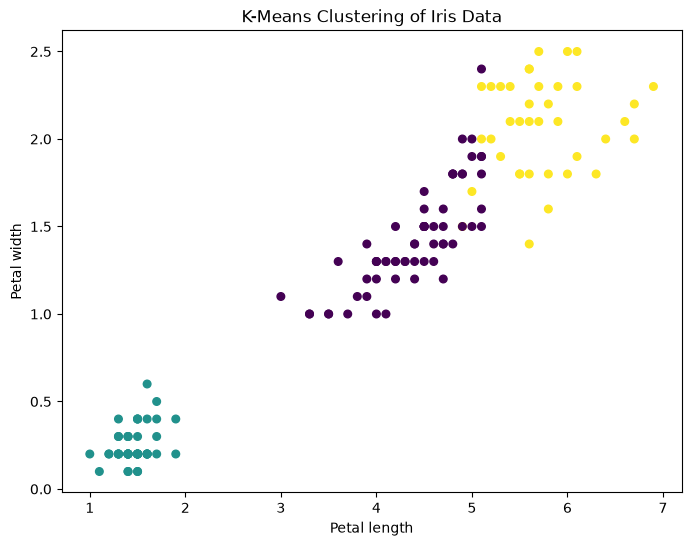

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 2],
    X[:, 3],
    c=iris_clusters,
    s=30
)

plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.title("K-Means Clustering of Iris Data")
plt.show()

# Task 9.1 – Interpretation

**1. Do the observations appear to form distinct groups?**
**Answer:** Partly. One group (bottom-left, short and narrow petals) is completely separate. The other two groups sit next to each other in one long cloud with no gap between them.

**2. Which features appear to provide useful separation?**
**Answer:** Petal length and petal width. The cluster centres differ most on these: petal length is 1.46, 4.39 and 5.74 cm for the three clusters. Sepal width hardly differs (2.75, 3.43, 3.07).

**3. Are the clusters perfectly separated?**
**Answer:** No. The small-petal cluster is perfectly separated, but the medium and large clusters touch. K-Means just draws a cut line through the middle of the shared cloud.

**4. Why might some observations be difficult to assign to a single cluster?**
**Answer:** Some flowers sit right where the medium and large groups meet, so they are almost the same distance from both centroids. A small change in a measurement could flip them to the other cluster. Real flowers vary, so the groups naturally overlap.

In [24]:
print("Original species:")
print(iris.target_names)

print("\nFirst 20 known labels:")
print(y[:20])

print("\nFirst 20 cluster assignments:")
print(iris_clusters[:20])

Original species:
['setosa' 'versicolor' 'virginica']

First 20 known labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 cluster assignments:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [25]:
# Extra check: cross-table of true species vs cluster found
import pandas as pd

pd.crosstab(
    pd.Series(iris.target_names[y], name="Species"),
    pd.Series(iris_clusters, name="Cluster")
)

Cluster,0,1,2
Species,,,
setosa,0,50,0
versicolor,48,0,2
virginica,14,0,36


# Task 9.2 – Interpretation

**1. How well do the discovered clusters correspond visually to the known species?**
**Answer:** Quite well, but not perfectly. Cluster 1 = all 50 setosa (perfect). Cluster 0 = 48 versicolor + 14 virginica. Cluster 2 = 36 virginica + 2 versicolor. So 134 of 150 flowers (about 89%) land in the “right” group, and the 16 mistakes are all between versicolor and virginica.

**2. Why should we not directly compare cluster number 0 with species label 0?**
**Answer:** The cluster numbers are just name tags K-Means made up. The first 20 flowers are all species 0 (setosa), but K-Means called them cluster 1. Comparing 0 with 0 would make it look like K-Means got all of them wrong, when actually it grouped them perfectly. You first have to match each cluster to the species it mostly contains.

**3. What does this experiment tell us about the difference between clustering and classification?**
**Answer:** Classification learns from labelled examples and predicts names we gave it (“virginica”). Clustering gets no labels and only finds groups of similar points; it cannot name them. K-Means rediscovered the species structure fairly well on its own, but it cannot split groups that overlap in the data, and a human still has to decide what each cluster means.